# 이미지 & 시퀀스 딥러닝


___
# 합성곱 신경망 (CNN, Convolutional NN)
---

## 픽셀과 채널

### 픽셀의 개념
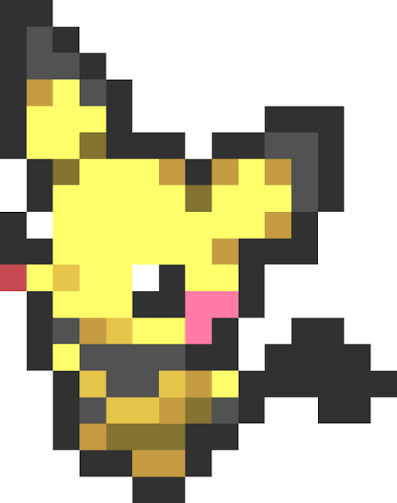

핸드폰으로 찍은 사진을 계속 확대하면 작은 네모 점들이 보이는데 이 점 하나가 픽셀입니다. 위에 첨부된 피츄처럼 점 하나하나가 합쳐져서 하나의 그림을 만듭니다. 
저희 눈에는 사진이지만 컴퓨터는 이 픽셀들의 숫자 배열처럼 인식을 하겠죠? 값은 보통 0부터 255까지의 값이 나와 이 값하나하나가 색을 특정해줍니다.

#### 이미지 데이터에서의 픽셀의 활용

흑백 이미지의 크기는 세로 픽셀 수 × 가로 픽셀 수로 표현합니다. (28 × 28) 이미지는 세로 28개, 가로 28개의 픽셀로 이루어져 있다는 뜻입니다.

#### 픽셀 값의 표현 방법

- 흑백(Grayscale) 이미지
    - 픽셀 값 하나로 밝기를 표현합니다. 0은 검은색, 255는 흰색이고 그 사이 값은 회색입니다.
- 컬러(RGB) 이미지
    - 픽셀 하나를 빨강, 초록, 파랑 세 가지 값으로 표현하고, 세 값의 조합으로 색이 만들어집니다.

### 채널

채널은 픽셀 하나를 몇 개의 숫자로 표현하는지를 말합니다. 흑백 이미지는 밝기 하나면 되니까 1채널이고, 컬러 이미지는 빨강, 초록, 파랑이 필요해서 3채널입니다. 
그래서 같은 28×28 이미지라도 흑백은 28×28×1개, 컬러는 28×28×3개의 숫자가 필요합니다.

### 색공간

색공간은 색을 어떤 기준의 숫자로 나타낼지 정해둔 방식입니다.

#### 그레이 스케일

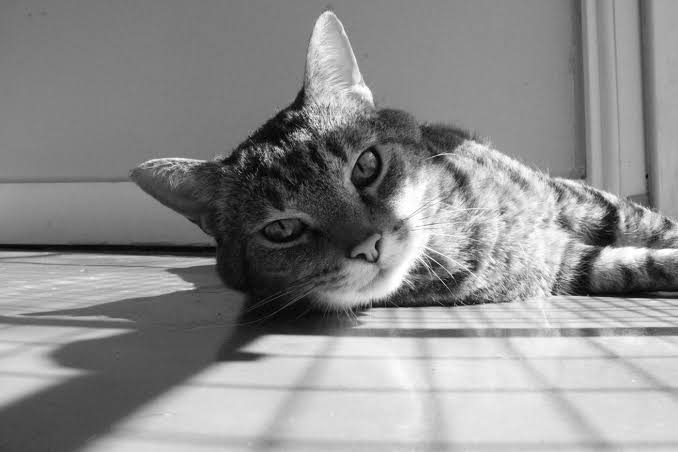
- Grayscale
    - 밝기 하나로만 나타냅니다. 0이면 검은색, 255면 흰색입니다.

밝기 값 하나만 저장하면 되기 때문에 채널이 1개이고, (28 × 28 × 1) 크기의 3차원 텐서로 표현합니다. NumPy에서는 채널을 생략해서 (28 × 28)로 저장하기도 합니다.

텐서는 다차원 데이터 배열을 통칭하는 말로, 스칼라는 0차원, 벡터는 1차원, 행렬은 2차원 텐서입니다.

#### RGB

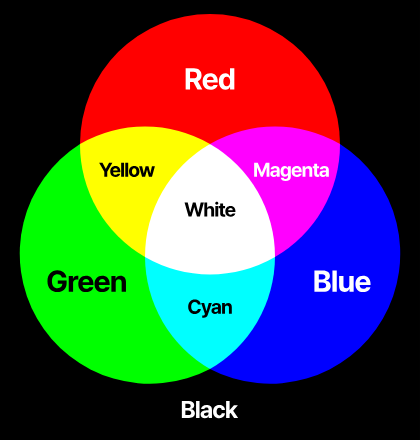

- RGB
    - 빨강, 초록, 파랑을 섞어서 색을 나타냅니다.

예를 들어 빨강과 초록이 높고 파랑이 낮으면 노란색 계열이 됩니다. 세 값이 합쳐져 하나의 색을 만들기 때문에 채널이 3개이고, (28 × 28 × 3) 크기의 3차원 텐서로 표현합니다. 채널은 깊이(depth)라고도 합니다.

#### HSV

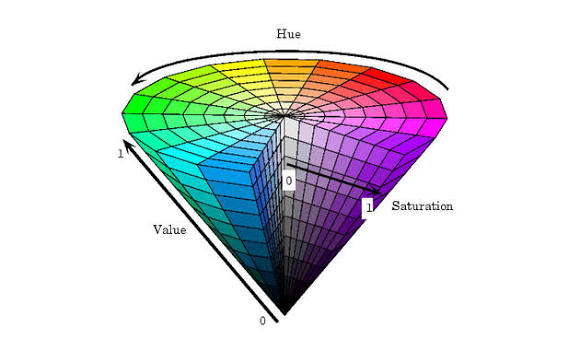

- HSV
    - 색상(Hue), 채도(Saturation), 명도(Value)로 나타냅니다.

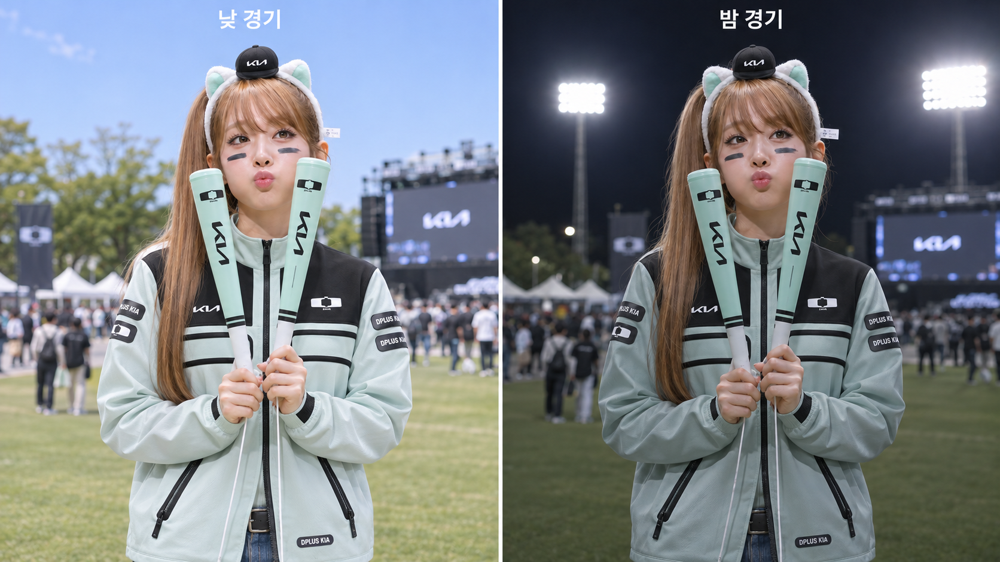

HSV가 왜 필요한지 예시를 들어보겠습니다. 제가 좋아하는 디플러스기아 유니폼을 사진에서 찾는다고 가정해보겠습니다. 낮 경기와 밤 경기는 조명이 달라서 같은 유니폼이어도 RGB 값이 전부 달라집니다. 하지만 HSV는 색상과 밝기가 나누어져 있어서 밝기가 달라져도 색상 값은 크게 바뀌지 않기 때문에, 조명이 달라도 같은 색을 찾기 쉽습니다.

---

## CNN의 개념

### 이미지 인식 방법 차이

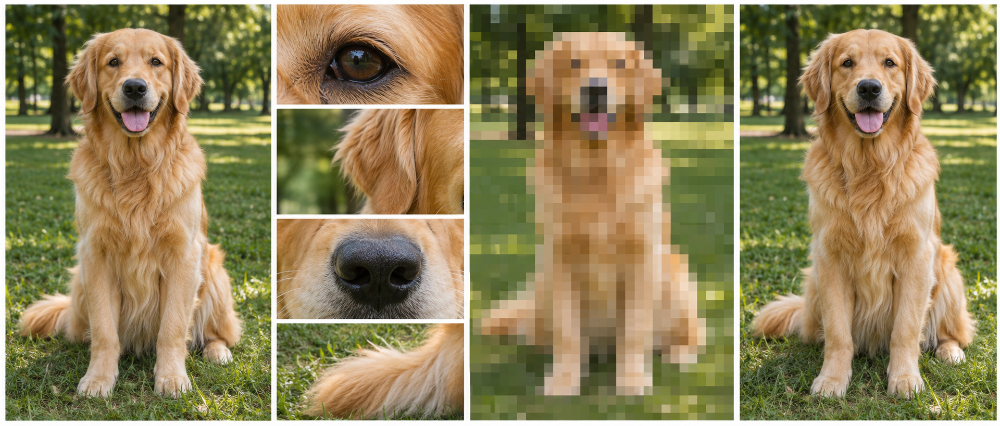

#### 사람이 이미지를 인식하는 방법

저희가 사진을 볼때 픽셀을 하나하나 보지 않죠? 
사진을 보면 눈, 귀, 코, 꼬리처럼 중요한 특징에 집중하고, 이 특징들을 종합해서 무엇인지 판단합니다.

#### 컴퓨터가 이미지를 인식하는 방법

반면에 컴퓨터는 사람과 달리 이미지를 픽셀 단위로 나누고 각 픽셀의 색상과 밝기 숫자를 처리합니다.
컴퓨터에게 이미지는 강아지라고 인지하지 않고 수많은 숫자 데이터로 인지한다고 생각하시면 됩니다.

#### 픽셀 정보를 그냥 학습하면 생기는 문제점

이미지를 1차원으로 펼쳐서 학습하면 가까이 있는 픽셀들의 관계가 모델에 직접 반영되지 않습니다. 
그래서 눈, 귀, 꼬리 같은 특징을 학습하기 어려워집니다.

### MLP와 CNN의 구조 비교

#### MLP = FC Layer + ... + FC Layer

입력 데이터를 FC Layer에 전달해서 학습하는 구조로, 이미지는 1차원 배열로 펼친 뒤 사용합니다.

#### CNN = (Conv + Pool) + ... + Flatten + FC Layer + ... + FC Layer

이미지의 공간적 특징을 유지하면서 Conv와 Pool을 반복해 특징을 뽑고, Flatten으로 1차원으로 바꾼 뒤 FC Layer로 분류합니다.

가장 큰 차이는 CNN에는 FC Layer 전에 Conv와 Pool로 이미지의 특징을 학습하는 과정이 추가된다는 점입니다.

### CNN
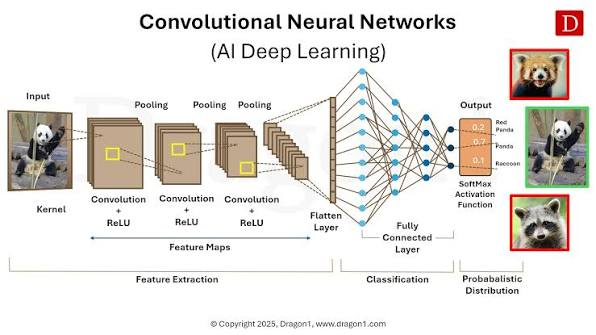

CNN은 이미지의 형태를 그대로 유지하면서 필터로 특징을 뽑아내는 신경망입니다.

#### CNN 모델의 전체 구조

입력 → 합성곱 + ReLU → 풀링 → (반복) → Flatten → 완전연결층 → 출력

크게 두 부분으로 나눌 수 있습니다.

- 특징 추출부
    - 합성곱층과 풀링층이 이미지의 특징을 뽑아냅니다.
- 분류부
    - 뽑아낸 특징을 1차원으로 펼치고, 완전연결층을 지나 최종 클래스를 예측합니다.

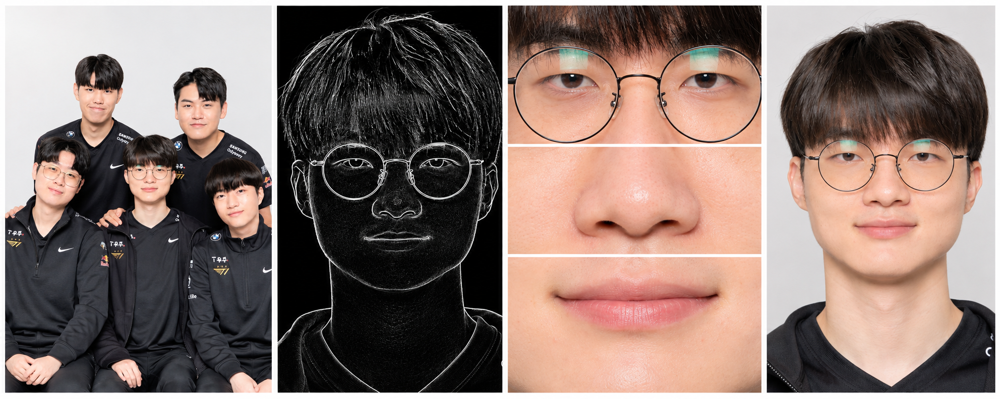

티원 단체 사진에서 멤버를 구분한다고 가정해보겠습니다. 앞쪽 층에서는 선이나 모서리 같은 단순한 특징을 찾고, 뒤로 갈수록 이를 조합해 눈, 코, 입을 찾고, 마지막에는 얼굴 전체를 보고 누구인지 판단한다고 생각하시면 됩니다.

---

## 왜 이미지 처리에 MLP가 아닌 CNN을 사용할까?

### 이미지 데이터의 구조

#### 흑백(grayscale) 이미지의 구조
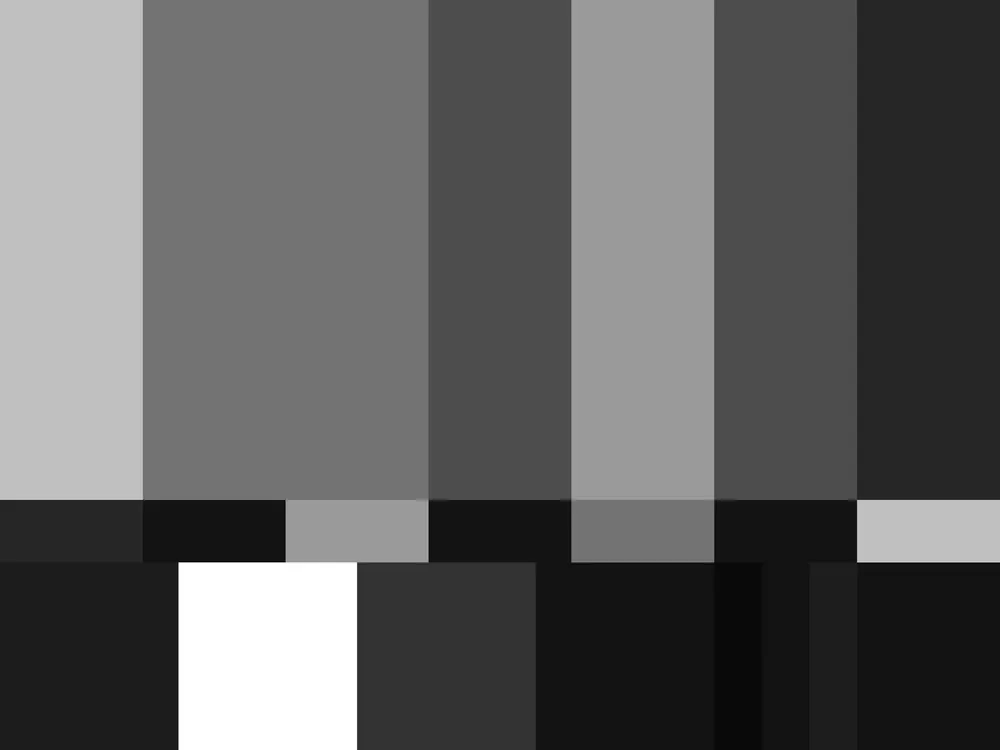

각 픽셀에 밝기 값 하나만 있어서 H는 세로 픽셀 수, W는 가로 픽셀 수로 두었을때 H × W 형태의 2차원 배열로 표현합니다. 

#### 컬러(RGB) 이미지의 구조

각 픽셀에 색상 값이 3개 있어서 H × W × 3 형태의 3차원 배열로 표현합니다.

#### 이미지 구조를 유지하는 모델이 필요한 이유

정형 데이터는 나이, 소득처럼 각 열이 독립적인 의미를 가집니다. 반면 이미지는 픽셀들이 가로세로로 연결되어 있어서 주변 픽셀과의 관계와 위치가 중요합니다. 그래서 이 구조를 유지하면서 학습하는 모델이 필요하고, 그 대표적인 모델이 CNN입니다.

### MLP의 한계

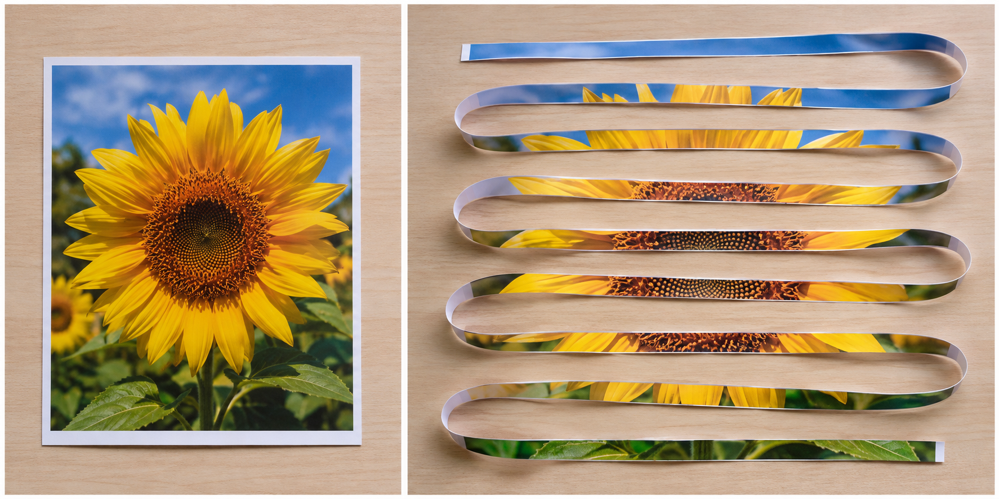

MLP는 이미지를 1차원으로 펼쳐서 입력받습니다. 사진을 가로로 길게 잘라서 한 줄로 이어붙인 것과 같은데요, 이렇게 하면 바로 위아래에 있던 픽셀이 서로 멀리 떨어지게 됩니다. 그래서 다음과 같은 문제가 생깁니다.


#### 위치, 크기, 회전 등의 변화에 취약 (Translation Variant)

MLP는 픽셀 위치마다 가중치를 학습합니다. 그래서 숫자 1이 조금만 옆으로 움직여도 입력이 크게 달라져서, 학습 때 못 본 위치나 형태가 나오면 성능이 크게 떨어집니다.

CNN은 같은 필터를 이미지의 여러 위치에 반복해서 적용하기 때문에 특징이 어디에 있어도 찾을 수 있고, Pooling이 작은 위치 변화에도 비슷한 특징을 유지하도록 도와줍니다.

#### 파라미터 폭발 (Parameter Explosion)

MLP는 이전 층의 모든 노드가 다음 층의 모든 노드와 연결되는 완전연결(Fully connected) 구조입니다. 그래서 1,000 × 1,000 이미지를 10,000개 노드에 연결하면 가중치가 약 100억 개나 필요합니다. 이렇게 되면 과적합 가능성이 높아지고 이미지가 클수록 학습이 느려집니다.

CNN은 작은 영역에만 필터를 적용하는 부분 연결 구조이고, 같은 필터의 가중치를 여러 위치에서 공유합니다. 그래서 3 × 3 필터 32개를 쓰면 파라미터가 320개면 되고, 이미지가 커져도 필터의 크기와 개수가 같다면 파라미터 수가 크게 늘지 않습니다.

#### 공간 정보 손실 (Loss of Spatial Info)

MLP는 Flatten으로 이미지를 1차원으로 펼칩니다. 28 × 28 이미지는 784개의 값이 되는데, 값 자체가 사라지는 것은 아니지만 어떤 픽셀들이 가까이 있었는지에 대한 2차원 구조는 명시적으로 유지되지 않습니다.

CNN은 H × W × C 구조를 유지한 채로 작은 영역을 연산해서 주변 픽셀의 관계를 활용하고, 특징을 먼저 학습한 다음에 Flatten을 합니다.

---

## 합성곱(Convolution)과 풀링(Pooling)

### Convolution Layer

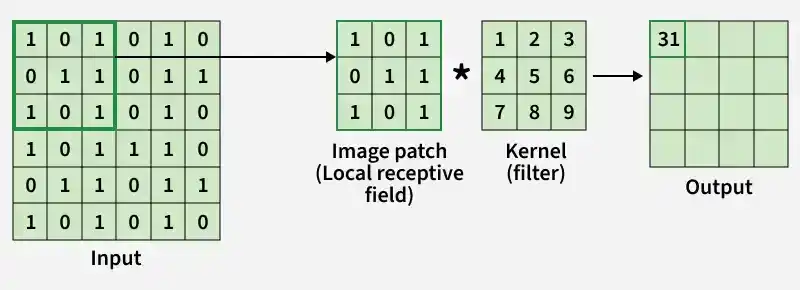


입력 이미지를 일정한 크기의 필터로 훑으면서 특징을 추출하고 학습하는 층입니다. 필터는 수직선, 수평선, 모서리, 질감 같은 패턴을 감지합니다.

돋보기를 들고 사진을 왼쪽 위부터 한 칸씩 훑으면서 내가 찾는 무늬가 있는지 확인하는 과정이라고 생각하시면 됩니다.

연산은 다음 순서로 진행됩니다.

1. 필터를 이미지 왼쪽 위에 놓고 정해진 간격만큼 이동하먀, 한 행이 끝나면 다음 행으로 내려갑니다.
2. 각 위치에서 픽셀 값과 필터의 가중치를 같은 위치끼리 곱하고, 모두 더해서 숫자 하나를 만듭니다.
3. 이 값을 Feature Map의 해당 위치에 저장합니다.

필터와 커널은 거의 같은 의미로 쓰이지만 정확히는 다릅니다.

- 커널
    - 패턴을 추출하는 2차원 가중치 행렬입니다.
- 필터
    - 커널의 묶음입니다. RGB 이미지라면 채널마다 하나씩 3개의 커널을 묶은 것이 필터 하나입니다.

Feature Map은 Convolution 연산의 결과로, 필터가 특징에 강하게 반응한 위치일수록 값이 커집니다. Feature Map의 개수는 필터의 개수로 결정되어서 필터를 6개 쓰면 Feature Map도 6개가 됩니다. 세로선을 찾는 필터와 가로선을 찾는 필터처럼 필터마다 다른 특징을 뽑습니다.

---

### Padding

Convolution 전에 이미지 가장자리에 픽셀을 추가하는 방법으로, 보통 0을 넣는 Zero Padding을 사용합니다. 사진에 액자를 끼운다고 생각하시면 됩니다.

패딩이 없으면 가장자리에는 필터가 적게 적용됩니다. 예를 들어 4 × 4 이미지에 3 × 3 필터를 적용하면 결과가 3 × 3으로 줄어들지만, 패딩을 1로 하면 입력이 6 × 6이 되어 결과가 4 × 4로 유지됩니다. 즉 패딩은 크기를 유지하면서 가장자리 특징까지 학습하게 해줍니다.

### Stride (보폭)

필터가 한 번에 이동하는 칸 수로, 돋보기를 옮기는 보폭이라고 볼 수 있습니다.

- Stride = 1
    - 한 칸씩 이동해서 세밀하게 보고, Feature Map이 상대적으로 큽니다.
- Stride = 2
    - 두 칸씩 이동해서 일부 위치를 건너뛰고, Feature Map이 상대적으로 작습니다.

보폭이 커질수록 연산량은 줄지만 세부 특징은 덜 보게 됩니다.

---

### Pooling

일정한 영역의 값을 하나로 요약해서 크기를 줄이는 과정입니다. 일반적으로 2 × 2 영역을 사용합니다. 풀링이 없으면 필터가 특정 픽셀 위치에서만 패턴을 찾게 되어서, 물체가 조금만 움직여도 같은 특징으로 인식하지 못합니다.

- Max Pooling: 영역에서 가장 큰 값을 선택합니다.
- Average Pooling: 영역의 평균을 계산합니다.

인사이콘에서 조별 점수를 정리한다고 가정해보겠습니다. 각 조에서 가장 높은 점수만 남기면 Max Pooling, 조의 평균 점수를 남기면 Average Pooling입니다.

장점은 계산량이 줄고, 작은 위치 변화에 강해지며, 과적합을 막는 데 도움이 되고, 노이즈의 영향이 완화된다는 것입니다. 단점은 세부 정보가 사라질 수 있고, 정확한 위치 정보가 줄어든다는 것입니다.

---

### CNN 구조 정리

Convolution Layer와 Pooling은 특징 추출을 담당하고, Padding과 Stride는 출력 크기와 정보 보존 정도를 조절하는 하이퍼파라미터입니다.

3채널 이미지는 R, G, B 채널을 필터의 각 채널과 따로 곱한 다음 전부 더해서 값 하나를 만듭니다. 그래서 필터 하나를 통과하면 출력 채널은 1개가 되고, 출력 채널을 늘리려면 필터를 여러 개 사용합니다.


___
# 이미지 딥러닝 응용
---


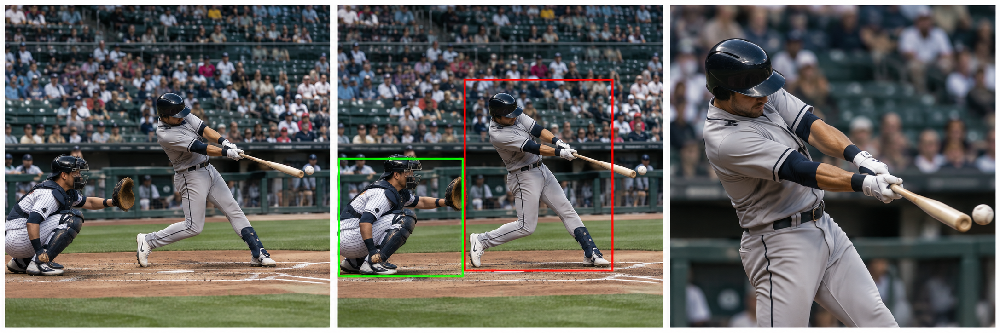

## 이미지 분류 (Image Classification)

이미지 전체가 정해진 클래스 중 어디에 속하는지 맞히는 문제입니다. 이 사진은 야구장이다 라고 답합니다.

## 객체 탐지 (Object Detection)

이미지 안에 있는 개별 객체의 종류와 위치를 함께 예측하는 문제입니다. 타자와 포수가 어디에 있는지 네모 박스로 표시합니다

CNN으로 Feature Map을 얻고 그 위에 두 개의 head를 올립니다.

- Classification Head: 객체의 종류를 예측합니다.
- Regression Head: Bounding Box의 위치와 크기를 예측합니다.


## 이미지 캡셔닝 (Image Captioning)

이미지의 내용을 문장으로 표현하는 문제입니다. 물체를 찾는 데서 끝나지 않고 물체들의 관계와 행동까지 파악해서, 타자가 공을 치고 있다 와 같은 문장을 만듭니다.

- CNN: 이미지의 특징을 추출합니다.
- Attention: 단어를 만들 때 그 단어와 관련된 이미지 영역에 더 높은 가중치를 줍니다.
- RNN: 이전에 만든 단어를 활용해 다음 단어를 예측하면서 문장을 완성합니다.


___
# RNN (Recurrent Neural Network)
---

## 순차(Sequence) 데이터

### 순차 데이터란?

데이터의 순서가 의미를 가져서, 순서를 바꾸면 정보가 달라지는 데이터입니다.

### 순차 데이터 세부 분류

순서의 기준으로 나누면 다음과 같습니다.

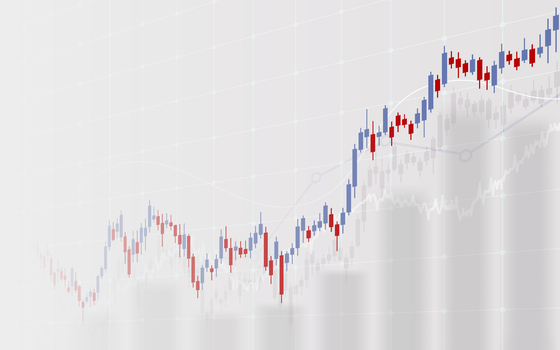
- 시간적 순차 데이터: 시간 순서를 따릅니다. (ex. 주가, 기온)

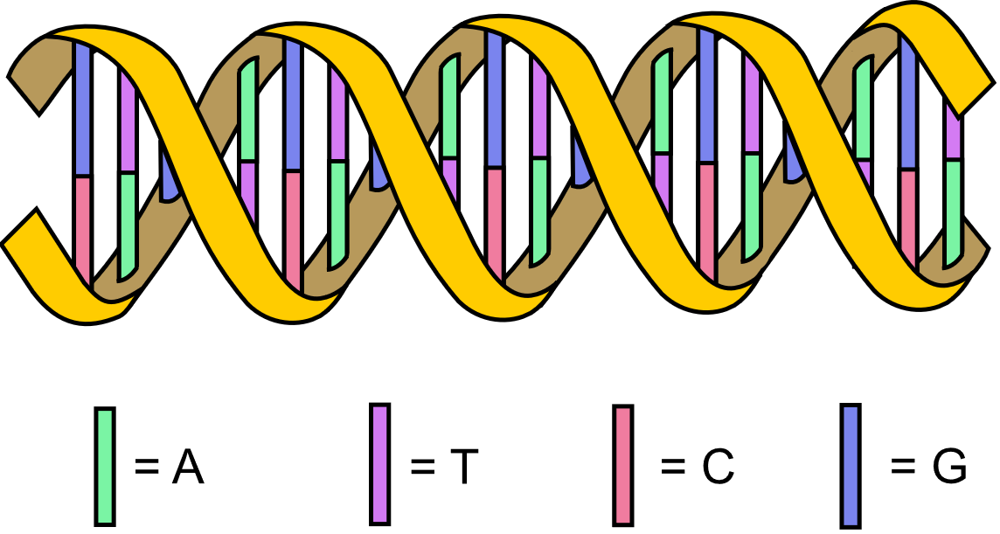
- 비시간적 순차 데이터: 위치나 순번을 따릅니다. (ex. 문장 내 단어, DNA 염기서열)

자료형으로 나누면 다음과 같습니다.

- 수치형: 값의 크기와 거리에 의미가 있습니다. (ex. 음성, 비디오)
- 범주형: 값의 크기와 거리에 의미가 없습니다. (ex. 웹 클릭 로그, 구매 이력)

### 기존 정형 데이터 vs. 순차 데이터

정형 데이터는 표 형태의 데이터로, 각 행이 서로 독립적입니다. 인사이트 지원자 명단을 이름순으로 놓든 지원순으로 놓든 내용이 달라지지 않는걸 생각하시면 되겠습니다.

순차 데이터는 순서를 바꾸면 의미가 달라지는데, 이를 순서의존성이라고 합니다. 제 키는 지금 182cm이고 중2때 175cm입니다. 이 순서라면 성장했다고 해석하지만, 순서를 바꾸면 키가 줄었다는 이야기가 됩니다. 문장도 마찬가지로 키움이 LG를 이겼다와 LG가 키움을 이겼다는 같은 단어를 써도 뜻이 정반대입니다.

또 이전 시점이 현재 시점에 영향을 주는데, 이를 자기상관성이라고 합니다.

회귀, 결정트리, SVM 같은 기존 머신러닝 기법은 정형 데이터를 전제로 만들어져서 순차 데이터를 다루는 데 한계가 있습니다. 그래서 RNN이 필요합니다.

---

## RNN(Recurrent Neural Network, 순환신경망)의 구조와 원리

### 구조

기존 신경망과 가장 큰 차이는 은닉층에 순환 구조가 있다는 것입니다.

- 입력층 $x$: 각 시점의 입력 $x_t$를 받습니다.
- 은닉층 $h$: 현재 입력 $x_t$와 이전 은닉 상태 $h_{t-1}$을 받아 새로운 은닉 상태 $h_t$를 만듭니다.
- 출력층 $o$: $h_t$를 바탕으로 결과 $o_t$를 내보냅니다.
- 입력 가중치 $U$: 입력을 은닉층으로 보낼 때 붙습니다.
- 순환 가중치 $V$: 이전 은닉 상태를 현재 은닉층으로 보낼 때 붙습니다.
- 출력 가중치 $W$: 은닉 상태를 출력으로 바꿀 때 붙습니다.

### 원리

매 시점마다 현재 입력과 이전 은닉 상태로 현재 은닉 상태를 계산하고, 그 결과를 다음 시점으로 넘깁니다.

tanh는 값을 -1에서 1 사이로 제한해서 은닉 상태가 폭주하는 것을 막고 비선형성을 더해줍니다. $f$는 출력의 활성화 함수로, 이진 분류면 시그모이드, 다중 분류면 소프트맥스를 사용합니다.

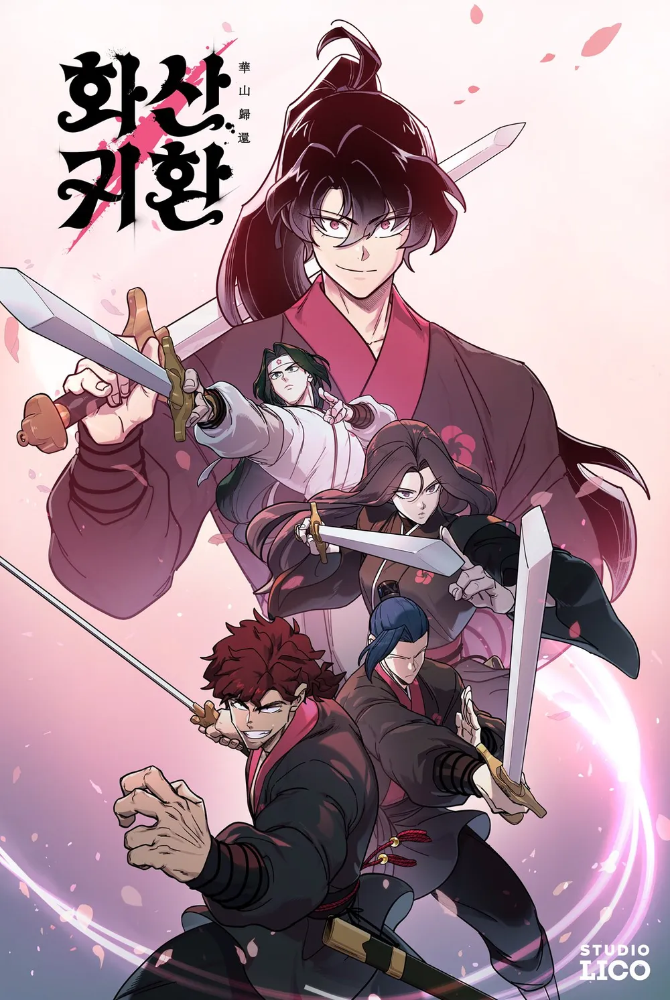

제가 화신귀환이란 웹툰을 1화부터 읽는다고 가정해보겠습니다. 이번 화의 내용이 $x_t$, 지난 화까지의 줄거리가 $h_{t-1}$이고, 둘을 합쳐서 머릿속에 새로 정리된 줄거리가 $h_t$입니다. 앞 내용을 기억하고 있어야 이번 화가 이해되는 것처럼, RNN도 이전 기억을 현재 입력과 함께 사용합니다.

또 매 화를 같은 사람이 같은 방식으로 읽듯이, RNN은 모든 시점에서 같은 가중치를 반복해서 사용합니다.

### RNN 아키텍처

- One to Many
    - 하나의 입력에서 시퀀스를 출력합니다. 사진 한 장을 보고 문장을 만드는 이미지 캡셔닝이 대표적입니다.
- Many to One
    - 시퀀스 입력에서 하나의 값을 출력합니다. 문장을 다 읽고 판별하는 스팸 메일 분류와 감성 분류가 있습니다.

- Many to Many
    - 시퀀스 입력에서 시퀀스를 출력합니다.
    - 동기식은 매 시점마다 바로 출력하며 객체 태깅 등에 쓰입니다.
    - 비동기식은 입력을 끝까지 읽고 출력하며 기계 번역, 요약 등에 쓰입니다.

---

## RNN의 한계 및 장기 의존성 문제

### RNN의 한계점

#### 시간에 따른 역전파(Back Propagation Through Time) 구조

RNN은 시간을 거슬러 올라가며 오차를 전파해 기울기를 계산합니다. 연쇄법칙 때문에 한 시점을 거슬러 갈 때마다 활성화 함수 미분값과 순환 가중치가 곱해지는데, 모든 시점이 같은 순환 가중치를 공유해서 같은 값이 계속 곱해집니다.

#### 기울기 소실 (Vanishing Gradients)

곱해지는 값이 1보다 작으면 기울기가 과거로 갈수록 0에 가까워집니다. tanh의 미분값은 최대 1이어서 기본 RNN에서는 폭주보다 훨씬 자주 발생합니다. 가까운 시점은 학습되지만 먼 과거의 정보는 거의 반영되지 않습니다.

#### 기울기 폭주 (Exploding Gradients)

곱해지는 값이 1보다 크면 기울기가 과거로 갈수록 매우 커집니다. 오차가 치솟거나 오르락내리락 진동하고, 심하면 NaN이 나와 학습이 멈춥니다.지난학기에 일일호프에서 예시를 생각하시면 될것 같습니다

#### 느린 훈련 시간

1화를 읽어야 2화를 읽을 수 있듯이, 이전 시점의 계산이 끝나야 다음 시점을 계산할 수 있어서 병렬 처리가 어렵습니다. 또 역전파를 위해 모든 시점의 은닉 상태를 저장해야 해서 메모리 부담도 큽니다.

### 장기 의존성 문제 (Long-Term Dependency Problem)

세 가지 한계는 결국 하나의 문제로 이어집니다. 관련된 정보가 멀리 떨어져 있을수록 RNN이 그 관계를 기억하고 학습하지 못하는 문제입니다. 웹툰 1화에 나온 복선을 100화쯤 가면 잊어버리는 것과 같습니다.

그래서 중요한 정보는 오래 기억하고 불필요한 정보는 잊는 메모리 구조가 필요합니다.

---

___
# LSTM & GRU
---

## LSTM & GRU

두 모델 모두 게이트로 무엇을 기억하고 무엇을 잊을지 정합니다. 게이트는 0에서 1 사이의 값을 정보에 곱해서, 0이면 버리고 1이면 그대로 유지합니다. 이 값은 현재 입력과 이전 은닉 상태를 보고 시그모이드로 계산합니다.

### LSTM

셀 상태 $C$는 장기 기억, 은닉 상태 $h$는 단기 기억이자 출력을 담당합니다. 
아까의 화신귀환 예시로 보면, 머릿속 기억과 별개로 중요한 내용을 적어두는 노트가 하나 생긴 것입니다. 이 노트가 셀 상태입니다.

- Forget Gate
    - 장기 기억에서 더 이상 필요 없는 내용을 지웁니다. 노트에서 이제 필요 없는 내용을 지우는 것입니다.
- Input Gate
    - 새 정보 중 중요한 것만 장기 기억에 저장합니다. 이번 화에서 복선이 나왔다면 노트에 적습니다.
- Output Gate
    - 장기 기억 중 지금 필요한 부분만 꺼내 단기 기억으로 내보냅니다. 노트에서 이번 화를 이해하는 데 필요한 내용만 꺼내봅니다.


### GRU

셀 상태 없이 은닉 상태 $h$ 하나에 기억과 출력을 모두 담습니다.

- Update Gate
    - 과거 기억과 새 정보를 몇 대 몇으로 섞을지 정합니다. LSTM의 Forget Gate와 Input Gate의 역할을 합친 것입니다.
- Reset Gate
    - 새 정보를 해석할 때 과거 기억을 얼마나 무시할지 정합니다. 새로운 시즌이 시작되어 이전 줄거리가 별로 필요 없다면 많이 무시합니다.

---

## LSTM

### LSTM (Long Short Term Memory) 구조

셀 상태는 시점을 따라 쭉 이어지는 선으로, 정보가 큰 변화 없이 다음 시점으로 흘러갑니다. 게이트가 여기서 정보를 빼거나 더합니다. RNN이 매 시점 은닉 상태를 통째로 덮어쓰는 것과 달리, LSTM은 필요한 것만 지우고 더합니다.

### 단계별로 알아보는 LSTM

LSTM은 이전 은닉 상태와 현재 입력을 함께 보고 네 단계를 거칩니다.

#### Forget gate : 무엇을 잊을까?

이전 셀 상태에서 무엇을 얼마나 남길지 정합니다. 게이트 값이 1에 가까우면 그대로 유지하고, 0에 가까우면 잊습니다.

#### Input gate : 무엇을 새로 기억할까?

이번 시점에 기억할 수도 있는 후보 정보를 만들고, 그중 얼마나 반영할지 정합니다.

#### Final memory cell : 기억 업데이트

앞에서 남긴 이전 기억에 새로 고른 정보를 더해서 셀 상태를 업데이트합니다. 곱셈이 아니라 덧셈으로 이어지는 것이 핵심입니다.

#### Output gate : 무엇을 내보낼까?

셀 상태 중 어느 부분을 내보낼지 정합니다. 셀 상태를 -1에서 1 사이로 정리한 뒤 필요한 부분만 은닉 상태로 출력합니다.

### LSTM의 장단점

장점은 덧셈 구조 덕분에 기울기가 먼 과거까지 전달되어 기울기 소실이 완화되고, 긴 시퀀스 과제에서 RNN보다 성능이 좋다는 것입니다. 그래서 1화의 복선을 훨씬 오래 가져갈 수 있습니다.

단점은 계산량이 많아 느리고 메모리를 많이 쓰며, 여전히 시점을 순서대로 계산해야 해서 병렬 처리가 안 된다는 것입니다. 또 기울기 소실을 없앤 것이 아니라 완화한 것이어서 매우 긴 시퀀스에서는 여전히 한계가 있습니다. 이것이 더 단순한 GRU가 나온 배경입니다.

---

## GRU

### GRU 의 정의

게이트로 정보를 선택적으로 기억하고 지운다는 LSTM의 핵심은 유지하면서 구조를 단순하게 줄인 모델입니다. 2014년 조경현 박사가 처음 제안했습니다.

### LSTM과의 차이점

- Forget gate와 Input gate를 Update gate 하나로 통합
    - 예를 들어 $z_t$가 0.3이면 과거 기억 70%에 새 정보 30%를 섞습니다.
- Reset gate를 사용
- Output gate가 없음
    - 은닉 상태 $h_t$를 그대로 출력합니다.
- Gate의 개수가 3개에서 2개로 감소
    - 파라미터가 LSTM의 약 3/4라서 학습 시간이 짧아지는데, 성능은 비슷하거나 과제에 따라 더 좋기도 합니다.

### GRU의 장단점

장점은 구조가 단순해서 이해와 구현이 쉽고, 학습이 빠르고 메모리를 적게 쓰며, 데이터가 적어도 학습이 안정적입니다.

단점은 장기 기억과 출력을 분리하지 못하고, 잊는 양과 더하는 양을 따로 조절할 수 없어 정교함이 떨어진다는 것입니다. 데이터가 많고 복잡한 과제는 LSTM을 주로 사용하고 있습니다.


## LSTM vs GRU

두 모델은 우열 관계가 아니라 정교함과 효율 사이의 선택입니다. 데이터가 많고 복잡한 과제라면 기억을 정교하게 관리하는 LSTM이 더 나을 수 있고, 데이터가 적거나 빠른 학습이 필요하다면 구조가 단순한 GRU가 적합합니다.

---

___
# Seq2Seq
---

## Seq2Seq의 기본 구조: 인코더와 디코더

Seq2Seq는 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델로, 입력과 출력의 길이가 달라도 됩니다. Many to Many를 두 개의 RNN으로 나눠 구현한 구조이고, 기계 번역, 챗봇, 문서 요약, 음성 인식에 사용됩니다.


### 인코더

입력 문장을 순서대로 읽고 문장 전체의 정보를 컨텍스트 벡터 하나로 압축합니다.

추가로 문장을 단어로 나누는 토큰화, 단어를 숫자 벡터로 바꾸는 임베딩을 거쳐 LSTM에 한 단어씩 넣습니다.

### 디코더

컨텍스트 벡터를 첫 은닉 상태로 받아 출력 문장을 한 단어씩 만듭니다.

시작 신호를 첫 입력으로 넣고, 매 시점 소프트맥스로 다음 단어의 확률을 계산해 가장 높은 단어를 고릅니다. 방금 고른 단어를 다음 입력으로 다시 넣고, 종료 신호가 나오면 멈춥니다.

예를 들어 저는 학생입니다를 번역한다면, 인코더가 문장을 벡터로 압축하고 디코더가 그 벡터를 보고 I, am, a, student를 차례대로 출력합니다.

### 컨텍스트 벡터 

인코더가 문장을 읽고 만든 요약 벡터입니다. 인코더 LSTM의 마지막 은닉 상태이고(LSTM이면 셀 상태도 함께 넘깁니다) 인코더와 디코더를 잇는 유일한 통로입니다.

크기는 사람이 정하는 하이퍼파라미터로 보통 256, 512, 1024 같은 값을 쓰고, 디코더의 은닉 상태 크기도 같게 맞춥니다. 크면 정보를 많이 담지만 계산량이 늘고 과적합 위험이 있으며, 작으면 빠르지만 긴 문장을 다 담지 못합니다.

---

## Seq2Seq의 한계

### 병목 현상

입력 문장 전체를 고정된 크기의 컨텍스트 벡터 하나에 압축하면서 정보가 손실되는 현상입니다. 두 시간짜리 회의를 포스트잇 한 장에 정리할 수 없는 것과 같습니다.

5단어든 50단어든 같은 크기에 담아야 해서 긴 문장일수록 손실이 커지고, 앞 단어는 여러 시점을 거치며 희미해져서 장기 의존성 문제도 여전히 남아 있습니다. 그래서 입력이 길어질수록 번역 품질이 크게 떨어집니다.

---